# MRFlow: Rectified-Flow MRI Modality Synthesis — Demo

This notebook shows the trained **MRFlow (DiT-S/2)** BraTS checkpoint generating a missing MRI
modality directly from raw `.nii.gz` files, and visualizes the **rectified-flow generation
trajectory** — how the predicted image is built up from pure noise at `t=0` to the final
image at `t=1`.

Pipeline: `raw NIfTI slice -> MedVAE encoder (latent) -> DiT-S/2 rectified flow (t=0->1) -> MedVAE decoder -> image`.

**Note:** only the `S_2` (small) architecture has been trained for this project (checkpoint:
`checkpoints/brats.pth`). `model.py` also defines `B`, `L`, and `XL` variants, but those have
not been trained — see the README for details.

## 1. Setup

In [1]:
import sys
sys.path.insert(0, 'src')  # so we can import model.py, utils.py, dataloader.py

import numpy as np
import nibabel as nib
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML
from torchmetrics.image.ssim import StructuralSimilarityIndexMeasure

from utils import load_config, create_model
from medvae import MVAE

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

/home/upadhya/anaconda3/envs/MRI_Gen/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


## 2. Point at a patient's raw NIfTI files

BraTS validation-style data ships one `.nii.gz` volume per modality per patient. Update
`PATIENT_DIR` / `PATIENT_ID` to point at any patient with the standard BraTS suffixes
(`t1n`, `t1c`, `t2w`, `t2f`). `SLICE_IDX` picks a single axial slice (out of ~155) to run
the 2D model on; slice 79 has a large, clearly visible tumor for this example patient.

In [2]:
PATIENT_DIR = '/raid/Users/mikhelson/baselines/brats24/ASNR-MICCAI-BraTS2023-GLI-Challenge-ValidationData/BraTS-GLI-00001-000'
PATIENT_ID = 'BraTS-GLI-00001-000'
SLICE_IDX = 79
IMG_SIZE = (256, 256)  # resolution the model/MedVAE were trained at

# BraTS modality name -> filename suffix used on disk
NIFTI_SUFFIX = {'t1': 't1n', 't1ce': 't1c', 't2': 't2w', 'flair': 't2f'}
MODALITY_INDEX = {'t1': 0, 't1ce': 1, 't2': 2, 'flair': 3}  # matches config.yaml modalities.brats


def load_slice(modality: str, slice_idx: int = SLICE_IDX) -> np.ndarray:
    """Load one axial slice of a raw BraTS volume, normalized to [0, 1]."""
    path = f'{PATIENT_DIR}/{PATIENT_ID}-{NIFTI_SUFFIX[modality]}.nii.gz'
    vol = nib.load(path).get_fdata().astype(np.float32)
    sl = vol[:, :, slice_idx]
    lo, hi = sl.min(), sl.max()
    return (sl - lo) / (hi - lo + 1e-8)

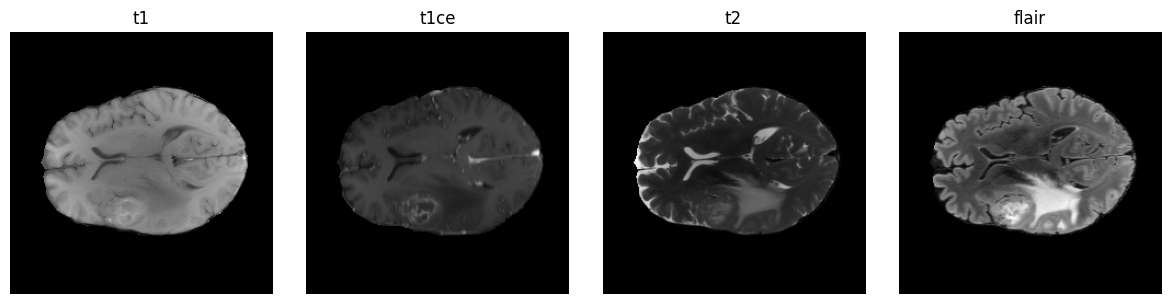

In [3]:
raw_slices = {m: load_slice(m) for m in ['t1', 't1ce', 't2', 'flair']}

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, (m, sl) in zip(axes, raw_slices.items()):
    ax.imshow(sl, cmap='gray')
    ax.set_title(m)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 3. Preprocess for the model

Two views of each slice are needed:
- A 3-channel, `[-1, 1]`-normalized, `256x256` tensor to feed MedVAE's encoder (it expects RGB-like input).
- The MedVAE latent (`post.mean`, shape `[3, 64, 64]`) is what the DiT model actually operates on.

In [4]:
def to_vae_input(slice_2d: np.ndarray) -> torch.Tensor:
    """[0,1] HxW slice -> [3, 256, 256] tensor in [-1, 1] for MedVAE."""
    t = torch.from_numpy(slice_2d).float().unsqueeze(0).repeat(3, 1, 1)  # [3, H, W]
    t = F.interpolate(t.unsqueeze(0), size=IMG_SIZE, mode='bilinear', align_corners=False).squeeze(0)
    return t * 2 - 1

## 4. Load the DiT-S/2 model and the frozen MedVAE

In [5]:
config = load_config('config/config.yaml')

model = create_model(config, dataset_name='brats')
ckpt = torch.load('checkpoints/brats.pth', map_location=device)
model.load_state_dict(ckpt['model'])
model.eval().to(device)
print(f"Loaded checkpoints/brats.pth (epoch {ckpt['epoch']}), {sum(p.numel() for p in model.parameters()):,} params")

medvae = MVAE(model_name=config['medvae']['model_name'], modality=config['medvae']['modality'])
medvae.eval().to(device)
medvae.requires_grad_(False);

Loaded checkpoints/brats.pth (epoch 195), 38,202,636 params


making attention of type 'vanilla' with 512 in_channels
Working with z of shape (1, 3, 64, 64) = 12288 dimensions.
making attention of type 'vanilla' with 512 in_channels
Restored from /home/upadhya/.cache/huggingface/hub/models--stanfordmimi--MedVAE/snapshots/8040c5ccb7a51eff6b4cef513c7f20bd1bda983d/model_weights/vae_4x_3c_2D.ckpt with 0 missing and 0 unexpected keys


## 5. Build the conditioning input

BraTS always has 3 non-target modality "slots" fed to the model (whichever are actually
available get their real latent; slots left out are zero-filled and flagged as missing).
Here we generate **FLAIR** from **T1 + T1CE only**, leaving **T2 missing** — showcasing the
model's core purpose (synthesizing a modality when others are unavailable). Change
`INPUT_MODALITIES` / `TARGET_MODALITY` to try any other combination (e.g. 1-to-1 from just
`['flair']` to `t2`, or 3-to-1 using all three other modalities).

In [7]:
INPUT_MODALITIES = ['t1', 't2']   # T2 slot is intentionally left missing
TARGET_MODALITY = 'flair'

# The 3 non-target modalities, in the dataset's canonical order -> the 3 fixed input slots
non_target = [m for m in ['t1', 't1ce', 't2', 'flair'] if m != TARGET_MODALITY]

slot_latents, input_imgs_mods = [], []
with torch.no_grad():
    for m in non_target:
        if m in INPUT_MODALITIES:
            vae_in = to_vae_input(raw_slices[m]).unsqueeze(0).to(device)
            input_imgs_mods.append(MODALITY_INDEX[m])
        else:
            vae_in = to_vae_input(np.zeros_like(raw_slices[m])).unsqueeze(0).to(device)
            input_imgs_mods.append(4)  # 4 = NA / missing modality
        _, posterior, _ = medvae.model(vae_in, decode=False)
        slot_latents.append(posterior.mean)

y_latent = torch.cat(slot_latents, dim=1)  # [1, 3*3, 64, 64]
input_imgs_mods = torch.tensor([input_imgs_mods], dtype=torch.int64, device=device)

one_hot_target = torch.zeros(1, 4, device=device)
one_hot_target[0, MODALITY_INDEX[TARGET_MODALITY]] = 1

print('Input slots (4 = missing):', dict(zip(non_target, input_imgs_mods[0].tolist())))
print(f'Target modality: {TARGET_MODALITY}')

Input slots (4 = missing): {'t1': 0, 't1ce': 4, 't2': 2}
Target modality: flair


## 6. Generate: integrate the rectified-flow ODE from t=0 to t=1

Rectified flow starts from Gaussian noise `x_0 ~ N(0, sigma^2 I)` at `t=0` and integrates a
learned velocity field up to `t=1`, where the result is the target modality's MedVAE latent.
We use the same 2nd-order **Heun** solver as `src/inference.py`, but decode the latent back to
image space at *every* step so we can watch the image form.

**Controlling the starting noise (`sigma`)** — this is the same `--sigma` flag documented in
`src/inference.py` / the README (`sigma=0.0` = deterministic, `sigma=1.0` = standard Gaussian).
`sigma` here is the **standard deviation** of the initial noise, so the *variance* of `x_0` is
`sigma**2`; e.g. `sigma=1.0` gives variance 1 (standard Gaussian), `sigma=0.0` gives variance 0
(a fixed all-zeros start — fully deterministic given the conditioning). As shown in the paper,
**`sigma=0` tends to produce smoother, more conservative outputs**, while **`sigma=1` tends to
produce higher-perceptual-quality, more detailed outputs** at the cost of some stochasticity
(different noise seeds give different fine detail). Pick the value you want to generate with:

In [8]:
SIGMA = 1.0  # try 0.0 (smooth, deterministic) vs 1.0 (higher perceptual detail, stochastic)

In [9]:
@torch.no_grad()
def decode_to_image(latent_z: torch.Tensor) -> np.ndarray:
    dec = medvae.model.decode(latent_z).clamp(-1, 1)
    img = (dec[:, 0] + 1) / 2  # first of the 3 (duplicated) output channels, back to [0, 1]
    return img[0].detach().cpu().numpy()


@torch.no_grad()
def generate_with_trajectory(y_latent, one_hot_target, input_imgs_mods, n_steps=30, seed=0, sigma=1.0):
    """Heun ODE integration from t=0 (noise) to t=1, returning every intermediate frame.

    x_0 ~ N(0, sigma**2 * I): sigma is the standard deviation of the starting noise
    (variance = sigma**2), matching the --sigma flag in src/inference.py.
    """
    eps, T = 1e-3, 1.0
    dt = 1.0 / n_steps
    t_scale = config['training']['t_scale']

    torch.manual_seed(seed)
    if sigma == 0:
        x = torch.zeros(1, 3, 64, 64, device=device)
    else:
        x = sigma * torch.randn(1, 3, 64, 64, device=device)
    frames = [(0.0, decode_to_image(x))]

    for i in range(n_steps):
        t_val = i / n_steps * (T - eps) + eps
        t_next_val = (i + 1) / n_steps * (T - eps) + eps
        t = torch.full((1,), t_val, device=device)
        t_next = torch.full((1,), t_next_val, device=device)

        k1 = model(x, t * t_scale, y_latent, one_hot_target, input_imgs_mods=input_imgs_mods)
        k2 = model(x + dt * k1, t_next * t_scale, y_latent, one_hot_target, input_imgs_mods=input_imgs_mods)
        x = x + dt * 0.5 * (k1 + k2)

        frames.append((t_next_val, decode_to_image(x)))
    return frames


frames = generate_with_trajectory(y_latent, one_hot_target, input_imgs_mods, n_steps=30, sigma=SIGMA)
print(f'Collected {len(frames)} frames spanning t=0 -> t=1 (sigma={SIGMA})')

Collected 31 frames spanning t=0 -> t=1 (sigma=1.0)


### Static trajectory: t=0 -> t=1

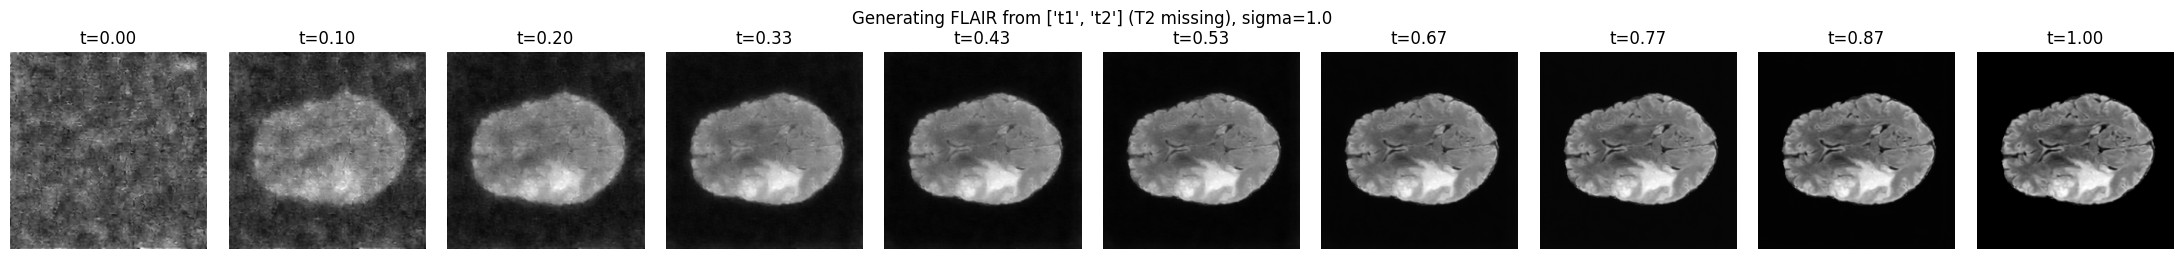

In [10]:
show_idx = np.linspace(0, len(frames) - 1, 10).astype(int)
fig, axes = plt.subplots(1, len(show_idx), figsize=(2.2 * len(show_idx), 2.6))
for ax, idx in zip(axes, show_idx):
    t_val, img = frames[idx]
    ax.imshow(img, cmap='gray')
    ax.set_title(f't={t_val:.2f}')
    ax.axis('off')
plt.suptitle(f'Generating {TARGET_MODALITY.upper()} from {INPUT_MODALITIES} (T2 missing), sigma={SIGMA}')
plt.tight_layout()
plt.show()

### Animated trajectory

Same frames, as a scrubbable inline animation (no ffmpeg required — rendered as embedded PNG frames + JS).

In [11]:
fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(frames[0][1], cmap='gray', vmin=0, vmax=1)
title = ax.set_title('t=0.00')
ax.axis('off')

def update(i):
    t_val, img = frames[i]
    im.set_data(img)
    title.set_text(f't={t_val:.2f}')
    return im, title

anim = animation.FuncAnimation(fig, update, frames=len(frames), interval=120, blit=False)
plt.close(fig)  # prevent duplicate static display
HTML(anim.to_jshtml())

## 7. Compare the final prediction to the ground-truth FLAIR

This patient happens to have all 4 modalities available, so we can hold FLAIR out as if it
were missing, generate it, and then check it against the real FLAIR scan.

PSNR: 21.97 dB | SSIM: 0.848


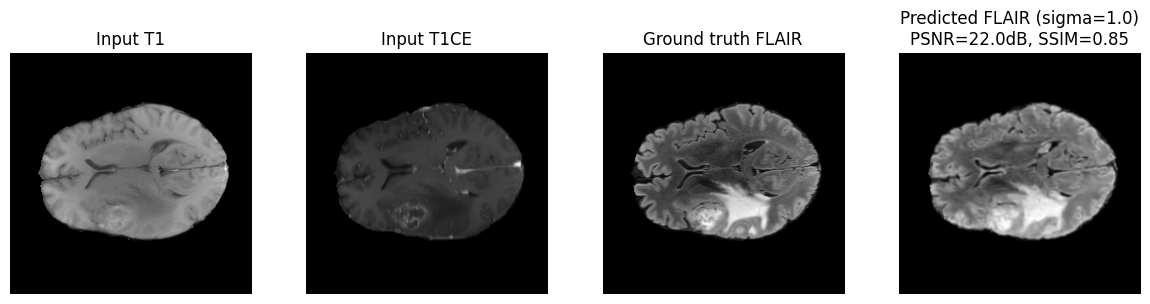

In [12]:
final_pred = frames[-1][1]
gt = raw_slices[TARGET_MODALITY]

# Resize prediction back to the original slice resolution for a fair pixel-wise comparison
pred_t = torch.from_numpy(final_pred)[None, None]
pred_resized = F.interpolate(pred_t, size=gt.shape, mode='bilinear', align_corners=False)[0, 0].numpy()

mse = np.mean((pred_resized - gt) ** 2)
psnr = 20 * np.log10(1.0 / np.sqrt(mse + 1e-12))
ssim_metric = StructuralSimilarityIndexMeasure(data_range=1.0)
ssim = ssim_metric(torch.from_numpy(pred_resized)[None, None].float(), torch.from_numpy(gt)[None, None].float()).item()
print(f'PSNR: {psnr:.2f} dB | SSIM: {ssim:.3f}')

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
axes[0].imshow(raw_slices['t1'], cmap='gray'); axes[0].set_title('Input T1'); axes[0].axis('off')
axes[1].imshow(raw_slices['t1ce'], cmap='gray'); axes[1].set_title('Input T1CE'); axes[1].axis('off')
axes[2].imshow(gt, cmap='gray'); axes[2].set_title(f'Ground truth {TARGET_MODALITY.upper()}'); axes[2].axis('off')
axes[3].imshow(pred_resized, cmap='gray'); axes[3].set_title(f'Predicted {TARGET_MODALITY.upper()} (sigma={SIGMA})\nPSNR={psnr:.1f}dB, SSIM={ssim:.2f}'); axes[3].axis('off')
plt.tight_layout()
plt.show()

## 7b. Effect of sigma: smooth (`sigma=0`) vs high-perceptual-detail (`sigma=1`)

As reported in the paper, the initial noise scale `sigma` (`x_0 ~ N(0, sigma**2 I)`) directly
trades off smoothness against perceptual detail: `sigma=0` is fully deterministic given the
conditioning and tends to produce smoother, more conservative reconstructions, while `sigma=1`
injects stochastic Gaussian noise and tends to recover more perceptual detail/texture (at the
cost of run-to-run variability across seeds). The cell below regenerates the same target at
a few different `sigma` values so you can compare directly and then pick whichever `SIGMA`
you prefer for the rest of the notebook.

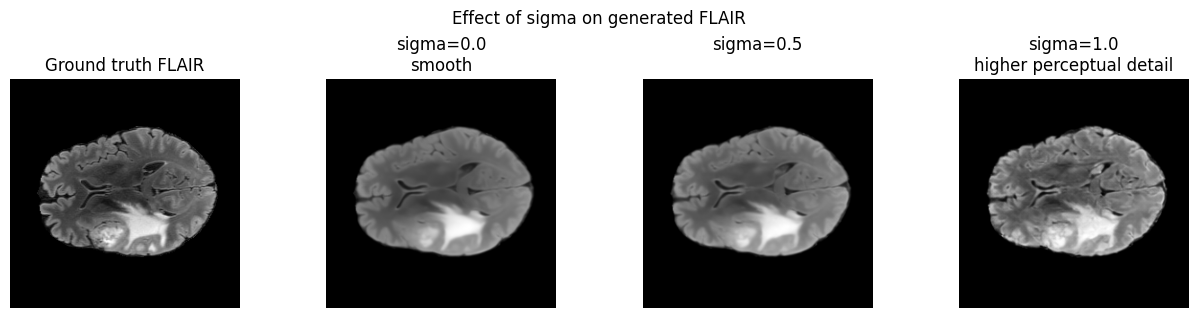

In [13]:
sigma_values = [0.0, 0.5, 1.0]
sigma_frames = {
    s: generate_with_trajectory(y_latent, one_hot_target, input_imgs_mods, n_steps=30, seed=0, sigma=s)
    for s in sigma_values
}

fig, axes = plt.subplots(1, len(sigma_values) + 1, figsize=(3.2 * (len(sigma_values) + 1), 3.2))
axes[0].imshow(gt, cmap='gray'); axes[0].set_title(f'Ground truth {TARGET_MODALITY.upper()}'); axes[0].axis('off')
for ax, s in zip(axes[1:], sigma_values):
    final_img = sigma_frames[s][-1][1]
    ax.imshow(final_img, cmap='gray')
    label = 'smooth' if s == 0 else ('higher perceptual detail' if s == 1 else '')
    ax.set_title(f'sigma={s}\n{label}')
    ax.axis('off')
plt.suptitle(f'Effect of sigma on generated {TARGET_MODALITY.upper()}')
plt.tight_layout()
plt.show()

## 8. Try another combination

Everything above is wrapped in reusable functions, so trying a different synthesis task is
just: rebuild the conditioning for the new input/target modalities, then re-run
`generate_with_trajectory`. Example below: a harder **1-to-1** case, T2 from FLAIR alone.

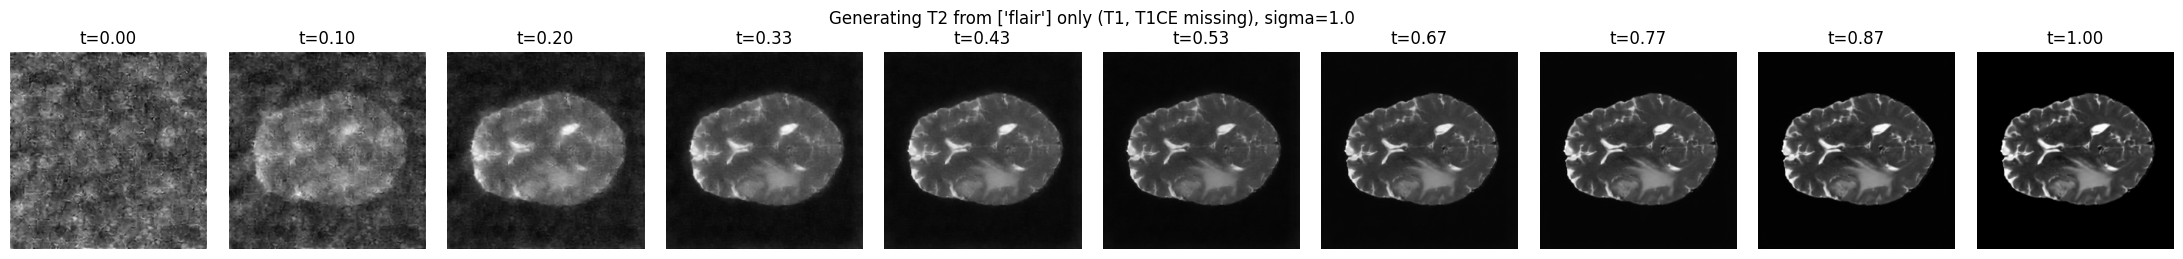

In [14]:
def build_conditioning(input_modalities, target_modality):
    non_target = [m for m in ['t1', 't1ce', 't2', 'flair'] if m != target_modality]
    slot_latents, mods = [], []
    with torch.no_grad():
        for m in non_target:
            if m in input_modalities:
                vae_in = to_vae_input(raw_slices[m]).unsqueeze(0).to(device)
                mods.append(MODALITY_INDEX[m])
            else:
                vae_in = to_vae_input(np.zeros_like(raw_slices[m])).unsqueeze(0).to(device)
                mods.append(4)
            _, posterior, _ = medvae.model(vae_in, decode=False)
            slot_latents.append(posterior.mean)
    y = torch.cat(slot_latents, dim=1)
    mods_t = torch.tensor([mods], dtype=torch.int64, device=device)
    oh = torch.zeros(1, 4, device=device)
    oh[0, MODALITY_INDEX[target_modality]] = 1
    return y, oh, mods_t


y2, oh2, mods2 = build_conditioning(input_modalities=['flair'], target_modality='t2')
frames2 = generate_with_trajectory(y2, oh2, mods2, n_steps=30, seed=1, sigma=SIGMA)

show_idx = np.linspace(0, len(frames2) - 1, 10).astype(int)
fig, axes = plt.subplots(1, len(show_idx), figsize=(2.2 * len(show_idx), 2.6))
for ax, idx in zip(axes, show_idx):
    t_val, img = frames2[idx]
    ax.imshow(img, cmap='gray')
    ax.set_title(f't={t_val:.2f}')
    ax.axis('off')
plt.suptitle(f"Generating T2 from ['flair'] only (T1, T1CE missing), sigma={SIGMA}")
plt.tight_layout()
plt.show()

## Notes

- Only the **S_2** (small, ~38M param) architecture has been trained for this project; that is
  the checkpoint used throughout this notebook (`checkpoints/brats.pth`). `model.py` also
  defines `B`, `L`, and `XL` variants for anyone who wants to try training larger models, but
  no checkpoints exist for them yet.
- This notebook runs 2D, slice-by-slice, exactly like the rest of the repo — 3D volume support
  is listed as a roadmap item in the README, not something currently implemented.
- `n_steps` in `generate_with_trajectory` trades off quality vs. speed, same as `--n_steps` in
  `src/inference.py`; 20-50 Heun steps is typically enough for good quality.
- `sigma` controls the standard deviation of the starting noise `x_0 ~ N(0, sigma**2 I)` (same
  `--sigma` flag as `src/inference.py`): `sigma=0` -> smoother/more conservative output,
  `sigma=1` -> higher perceptual detail but more seed-to-seed variability. See section 7b for a
  side-by-side comparison, and set `SIGMA` in section 6 to whichever value you prefer.